## 1. Loading and Observing

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("online_retail_II.csv",
                 dtype={"Invoice": str, "StockCode": str},
                 parse_dates=["InvoiceDate"])
print(df.shape)
print(df.dtypes)
df.head()

(1067371, 8)
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 2. Date range and the year 1 / year 2 split

In [10]:
print(df["InvoiceDate"].min(), "→", df["InvoiceDate"].max())
split = pd.Timestamp("2010-12-01")
print("train rows:", (df["InvoiceDate"] < split).sum(),
      "| replay rows:", (df["InvoiceDate"] >= split).sum())

2009-12-01 07:45:00 → 2011-12-09 12:50:00
train rows: 502938 | replay rows: 564433


## 3. Missing values and duplicates

In [13]:
print(df.isna().sum())
print("missing Customer ID share:", round(df["Customer ID"].isna().mean(), 3))
print("exact duplicate rows:", df.duplicated().sum())

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64
missing Customer ID share: 0.228
exact duplicate rows: 34335


## 4. Cancellations, adjustments, and bad quantities or prices

In [16]:
df["is_cancel"] = df["Invoice"].str.startswith("C")
print("invoice prefixes:", df["Invoice"].str.extract(r"^([A-Za-z]*)")[0].value_counts().to_dict())
print("cancelled rows:", df["is_cancel"].sum())
print("Quantity <= 0 (not cancelled):", ((df["Quantity"] <= 0) & ~df["is_cancel"]).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())
print(df[["Quantity", "Price"]].describe())

invoice prefixes: {'': 1047871, 'C': 19494, 'A': 6}
cancelled rows: 19494
Quantity <= 0 (not cancelled): 3457
Price <= 0: 6207
           Quantity         Price
count  1.067371e+06  1.067371e+06
mean   9.938898e+00  4.649388e+00
std    1.727058e+02  1.235531e+02
min   -8.099500e+04 -5.359436e+04
25%    1.000000e+00  1.250000e+00
50%    3.000000e+00  2.100000e+00
75%    1.000000e+01  4.150000e+00
max    8.099500e+04  3.897000e+04


## 5. Non-product stock codes

In [19]:
normal = df["StockCode"].str.match(r"^\d{5}[A-Za-z]{0,2}$")
odd = df.loc[~normal, ["StockCode", "Description"]]
odd.groupby("StockCode")["Description"].agg(["first", "count"]).sort_values("count", ascending=False).head(30)

,first,count
StockCode,,
POST,POSTAGE,2115
DOT,DOTCOM POSTAGE,1444
M,Manual,1421
C2,CARRIAGE,279
D,Discount,177
S,SAMPLES,104
BANK CHARGES,Bank Charges,102
ADJUST,Adjustment by john on 26/01/2010 16,67
AMAZONFEE,AMAZON FEE,43


## 6. Products whose description or price changes

In [22]:
prod = df[normal].groupby("StockCode").agg(desc_n=("Description", "nunique"),
                                           price_n=("Price", "nunique"))
print("products with >1 description:", (prod["desc_n"] > 1).sum(), "of", len(prod))
print("products with >1 price:", (prod["price_n"] > 1).sum())

products with >1 description: 1224 of 5242
products with >1 price: 4673


## 7. Daily volume, which becomes your batch size

trading days: 604
count     604.000000
mean     1767.170530
std       889.809149
min       279.000000
25%      1214.750000
50%      1566.500000
75%      2032.500000
max      7756.000000
dtype: float64
InvoiceDate
Thursday     203149
Tuesday      196626
Monday       189084
Wednesday    185051
Friday       153803
Sunday       139256
Saturday        402
Name: count, dtype: int64


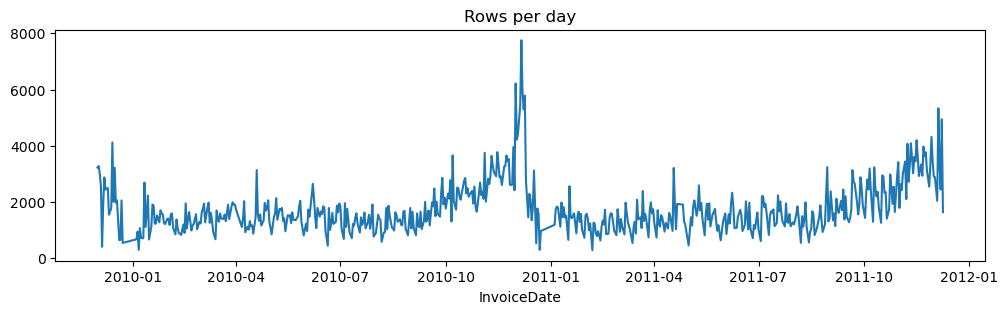

In [25]:
daily = df.groupby(df["InvoiceDate"].dt.date).size()
print("trading days:", len(daily))
print(daily.describe())
print(df["InvoiceDate"].dt.day_name().value_counts())
daily.plot(figsize=(12, 3), title="Rows per day"); plt.show()

## 8. Customers and countries

In [28]:
cust = df.dropna(subset=["Customer ID"])
print("customers:", cust["Customer ID"].nunique())
print(cust.groupby("Customer ID")["Invoice"].nunique().describe())
print(df["Country"].value_counts().head(10))

customers: 5942
count    5942.000000
mean        7.552339
std        15.972262
min         1.000000
25%         2.000000
50%         4.000000
75%         8.000000
max       510.000000
Name: Invoice, dtype: float64
Country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Spain               3811
Switzerland         3189
Belgium             3123
Portugal            2620
Australia           1913
Name: count, dtype: int64


## 9. Save as Parquet for faster loading later

In [31]:
df.drop(columns="is_cancel").to_parquet("online_retail_II.parquet", index=False)